In [46]:
#pip install pandas numpy scikit-learn matplotlib seaborn joblib
import csv                   # stdlib: used for safe CSV reading with quote handling
import os                    # stdlib: path resolution, environment-agnostic file access

import joblib                # third-party: efficient binary serialization of sklearn objects
import matplotlib.pyplot as plt   # third-party: low-level plotting API
import numpy as np                # third-party: numerical arrays and random state control
import pandas as pd               # third-party: DataFrame-based data manipulation
import seaborn as sns             # third-party: high-level statistical visualization
from sklearn.decomposition import TruncatedSVD          # Latent Semantic Analysis core
from sklearn.feature_extraction.text import TfidfVectorizer      # bag-of-words feature extraction
from sklearn.linear_model import LinearRegression       # OLS regression estimator
from sklearn.metrics import (
    mean_absolute_error,   # MAE: average absolute deviation — human-interpretable error unit
    mean_squared_error,    # MSE: penalises large errors more heavily than MAE
    r2_score,              # R²: fraction of variance explained — primary goodness-of-fit metric
)
from sklearn.metrics.pairwise import cosine_similarity   # pairwise angular distance in vector space
from sklearn.model_selection  import train_test_split    # stratified data partition
from sklearn.preprocessing    import Normalizer, QuantileTransformer  # scaling utilities

In [47]:
"""This function was added for a reason: when retraining, the model selects the same
 data sample it was previously trained on each time."""
np.random.seed(42)
pathResums = r'E:\University\3) 4_2\3- Machine Learning\Project\archive\Resume\Resume.csv'
resume_df = pd.read_csv(pathResums)
resume_df.head()

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [48]:
print(f"Number of Rows and column (Shape): {resume_df.shape}")

Number of Rows and column (Shape): (2484, 4)


In [49]:
resume_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ID           2484 non-null   int64
 1   Resume_str   2484 non-null   str  
 2   Resume_html  2484 non-null   str  
 3   Category     2484 non-null   str  
dtypes: int64(1), str(3)
memory usage: 77.8 KB


In [50]:
#Data Claening and  Preprocessing
print("\nNumber of data is Null")
missing_data = resume_df.isnull().sum()
print(missing_data[missing_data > 0])


Number of data is Null
Series([], dtype: int64)


In [51]:
print(f"\n Duplicates value (Duplicates) :{resume_df.duplicated().sum()}")


 Duplicates value (Duplicates) :0


In [52]:
displayColumns = resume_df.columns.tolist()
print(displayColumns)

['ID', 'Resume_str', 'Resume_html', 'Category']


In [53]:
print("Categories available:")
print(resume_df['Category'].value_counts())

Categories available:
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
FINANCE                   118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
AVIATION                  117
SALES                     116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


In [54]:
IT_ENG_df = resume_df[resume_df['Category'].isin(['INFORMATION-TECHNOLOGY', 'ENGINEERING'])]
print("I Need to Train Model Only INFORMATION-TECHNOLOGY And ENGINEERING")
print(f"Number of rows: {IT_ENG_df.shape[0]}")

I Need to Train Model Only INFORMATION-TECHNOLOGY And ENGINEERING
Number of rows: 238


In [55]:
# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Config ────────────────────────────────────────────────────────────────────
INPUT_FILE   = r"E:\University\3) 4_2\3- Machine Learning\Project\archive\Resume\Resume.csv"          # path to the raw dataset
OUTPUT_FILE  = "Final_Training_Data.csv"
SAMPLE_SIZE  = 238
LSA_COMPONENTS = 80

TARGET_CATEGORIES = ["INFORMATION-TECHNOLOGY", "ENGINEERING"]

# Static Job Description (matched against all 150 resumes)
JD = (
    "Software Engineer Data Analyst Machine Learning Python SQL "
    "FastAPI Power BI PostgreSQL Data Science Web Scraping"
)

# Human-eval rule thresholds
LEXICAL_HARD_CUTOFF     = 45   # below → Rule 1 fires
SEMANTIC_WEAK_THRESHOLD = 50   # below (with high lex) → Rule 2 fires
LEXICAL_STUFFING_CUTOFF = 80   # above (with low sem)  → Rule 2 fires
NOISE_LOW, NOISE_HIGH   = -8, 8
RULE1_MIN, RULE1_MAX    = 20, 45
RULE2_MIN, RULE2_MAX    = 45, 65

In [56]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 1 — Domain Filtering
# ══════════════════════════════════════════════════════════════════════════════
print("━" * 64)
print("  STEP 1 │ Domain Filtering")
print("━" * 64)

df_raw = pd.read_csv(INPUT_FILE)
print(f"  Raw rows : {len(df_raw):,}")

df_filtered = df_raw[df_raw["Category"].isin(TARGET_CATEGORIES)].copy()
print(f"  After filter : {len(df_filtered):,} rows")
for cat in TARGET_CATEGORIES:
    print(f"  {cat:<27}: {(df_filtered['Category'] == cat).sum()}")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STEP 1 │ Domain Filtering
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Raw rows : 2,484
  After filter : 238 rows
  INFORMATION-TECHNOLOGY     : 120
  ENGINEERING                : 118


In [57]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 2 — Random Sampling (exactly 150)
# ══════════════════════════════════════════════════════════════════════════════
print("\n" + "━" * 64)
print(f"  STEP 2 │ Sampling → {SAMPLE_SIZE} resumes  (SEED={SEED})")
print("━" * 64)

df = df_filtered.sample(n=SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)
for cat in TARGET_CATEGORIES:
    print(f"  {cat:<27}: {(df['Category'] == cat).sum()}")

resumes = df["Resume_str"].fillna("").astype(str).tolist()
corpus  = [JD] + resumes   # index-0 is always the JD



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STEP 2 │ Sampling → 238 resumes  (SEED=42)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  INFORMATION-TECHNOLOGY     : 120
  ENGINEERING                : 118


In [58]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 3 — Semantic Score  (LSA / TruncatedSVD)
#   TF-IDF (unigrams+bigrams, sublinear TF)
#   → TruncatedSVD (80 components, 10 iterations)
#   → L2 Normalizer  (unit vectors → dot product = cosine)
#   → cosine_similarity(JD_vec, resume_vecs)
#   → QuantileTransformer (uniform output) → scale to [0, 100]
# ══════════════════════════════════════════════════════════════════════════════
print("\n" + "━" * 64)
print("  STEP 3 │ Semantic Score  (LSA · SVD-80 · Quantile → [0,100])")
print("━" * 64)

vec_sem = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    sublinear_tf=True,
    max_df=0.95,
    min_df=1,
)
svd  = TruncatedSVD(n_components=LSA_COMPONENTS, n_iter=10, random_state=SEED)
norm = Normalizer(copy=False)

X_tfidf_sem = vec_sem.fit_transform(corpus)          # (151, vocab)
X_lsa       = svd.fit_transform(X_tfidf_sem)         # (151, 80)
norm.transform(X_lsa)                                # L2 unit vectors in-place

print(f"  Vocabulary size            : {X_tfidf_sem.shape[1]:,} terms")
print(f"  LSA components             : {LSA_COMPONENTS}")
print(f"  Variance explained         : {svd.explained_variance_ratio_.sum():.1%}")

raw_sem = cosine_similarity(X_lsa[0:1], X_lsa[1:])[0]   # (150,)

qt_sem  = QuantileTransformer(
    n_quantiles=SAMPLE_SIZE,
    output_distribution="uniform",
    random_state=SEED,
)
sem_scaled = qt_sem.fit_transform(raw_sem.reshape(-1, 1)).flatten() * 100
df["semantic_score"] = np.round(sem_scaled, 4)

print(f"  Raw cosine range           : [{raw_sem.min():.4f}, {raw_sem.max():.4f}]")
print(f"  Scaled mean ± std          : {df['semantic_score'].mean():.2f} ± {df['semantic_score'].std():.2f}")



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STEP 3 │ Semantic Score  (LSA · SVD-80 · Quantile → [0,100])
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Vocabulary size            : 119,433 terms
  LSA components             : 80
  Variance explained         : 38.8%
  Raw cosine range           : [-0.1573, 0.5956]
  Scaled mean ± std          : 50.00 ± 29.05


In [59]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 4 — Lexical Score  (TF-IDF Cosine, independent vectorizer)
#   Separate TF-IDF fit (no shared vocabulary with semantic step)
#   → cosine_similarity(JD_vec, resume_vecs)
#   → QuantileTransformer → [0, 100]
# ══════════════════════════════════════════════════════════════════════════════
print("\n" + "━" * 64)
print("  STEP 4 │ Lexical Score   (TF-IDF · Quantile → [0,100])")
print("━" * 64)

vec_lex = TfidfVectorizer(
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=1,
)
X_lex   = vec_lex.fit_transform(corpus)                  # (151, V)
raw_lex = cosine_similarity(X_lex[0], X_lex[1:])[0]     # (150,)

qt_lex  = QuantileTransformer(
    n_quantiles=SAMPLE_SIZE,
    output_distribution="uniform",
    random_state=SEED,
)
lex_scaled = qt_lex.fit_transform(raw_lex.reshape(-1, 1)).flatten() * 100
df["lexical_score"] = np.round(lex_scaled, 4)

print(f"  Raw TF-IDF cosine range    : [{raw_lex.min():.4f}, {raw_lex.max():.4f}]")
print(f"  Scaled mean ± std          : {df['lexical_score'].mean():.2f} ± {df['lexical_score'].std():.2f}")

# Feature independence verification
feat_corr = df["semantic_score"].corr(df["lexical_score"])
print(f"\n  Correlation sem ↔ lex      : {feat_corr:.4f}  "
      f"{'✓ independent signals' if abs(feat_corr) < 0.90 else '⚠ high correlation'}")

# Score band breakdown (shows all 3 rules will fire)
print(f"\n  Score bands (before human_eval):")
print(f"    lex < 45  (Rule 1 zone)  : {(df['lexical_score'] < LEXICAL_HARD_CUTOFF).sum():>3} resumes")
print(f"    45 ≤ lex ≤ 80 (Rule 3)  : "
      f"{((df['lexical_score'] >= LEXICAL_HARD_CUTOFF) & (df['lexical_score'] <= LEXICAL_STUFFING_CUTOFF)).sum():>3} resumes")
print(f"    lex > 80  (Rule 2/3)     : {(df['lexical_score'] > LEXICAL_STUFFING_CUTOFF).sum():>3} resumes")
print(f"    sem < 50                 : {(df['semantic_score'] < SEMANTIC_WEAK_THRESHOLD).sum():>3} resumes")
print(f"    sem ≥ 50                 : {(df['semantic_score'] >= SEMANTIC_WEAK_THRESHOLD).sum():>3} resumes")



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STEP 4 │ Lexical Score   (TF-IDF · Quantile → [0,100])
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Raw TF-IDF cosine range    : [0.0000, 0.0624]
  Scaled mean ± std          : 49.99 ± 29.06

  Correlation sem ↔ lex      : 0.4745  ✓ independent signals

  Score bands (before human_eval):
    lex < 45  (Rule 1 zone)  : 107 resumes
    45 ≤ lex ≤ 80 (Rule 3)  :  83 resumes
    lex > 80  (Rule 2/3)     :  48 resumes
    sem < 50                 : 119 resumes
    sem ≥ 50                 : 119 resumes


In [60]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 5 — Human Eval Score  (Hiring-Manager Logic + Noise)
#
#   Rule 1 — Lexical Hard-Filter Penalty
#             lex < 45 → random ∈ [20, 45]
#             Rationale: candidate fails keyword scan → automatic reject
#
#   Rule 2 — Overqualified / Keyword-Stuffing Penalty
#             sem < 50 AND lex > 80 → random ∈ [45, 65]
#             Rationale: buzzword-heavy CV, shallow conceptual depth → risky
#
#   Rule 3 — Sweet-Spot (Normal Range)
#             base = 0.55·lex + 0.45·sem
#             noise = randint(-8, +8)   ← human inconsistency / mood bias
#             final = clip(round(base + noise), 0, 100)
#
#   Anti-leakage: conditional branching + random noise ensure
#   Corr(human_eval, naive_formula) << 1.0  →  MLR learns real weights
# ══════════════════════════════════════════════════════════════════════════════
print("\n" + "━" * 64)
print("  STEP 5 │ Human Eval Score  (3-Rule Logic + ±8 Noise)")
print("━" * 64)


def simulate_human_eval(row: pd.Series) -> int:
    """
    Simulate a strict IT hiring manager's score for a single resume row.

    Parameters
    ----------
    row : pd.Series
        Must contain 'lexical_score' and 'semantic_score' (both 0–100).

    Returns
    -------
    int
        Human evaluation score in [0, 100].
    """
    lex = float(row["lexical_score"])
    sem = float(row["semantic_score"])

    # ── Rule 1: Hard keyword filter ──────────────────────────────────────────
    if lex < LEXICAL_HARD_CUTOFF:
        return int(np.random.randint(RULE1_MIN, RULE1_MAX + 1))

    # ── Rule 2: Keyword stuffing ─────────────────────────────────────────────
    if sem < SEMANTIC_WEAK_THRESHOLD and lex > LEXICAL_STUFFING_CUTOFF:
        return int(np.random.randint(RULE2_MIN, RULE2_MAX + 1))

    # ── Rule 3: Sweet-spot + human noise ─────────────────────────────────────
    base  = 0.55 * lex + 0.45 * sem
    noise = np.random.randint(NOISE_LOW, NOISE_HIGH + 1)
    return int(np.clip(round(base + noise), 0, 100))


df["human_eval_score"] = df.apply(simulate_human_eval, axis=1)

r1 = int((df["lexical_score"] < LEXICAL_HARD_CUTOFF).sum())
r2 = int(((df["semantic_score"] < SEMANTIC_WEAK_THRESHOLD) &
           (df["lexical_score"] > LEXICAL_STUFFING_CUTOFF)).sum())
r3 = SAMPLE_SIZE - r1 - r2

print(f"  Rule 1 (Hard-Filter)       : {r1:>3} resumes → ∈ [{RULE1_MIN}, {RULE1_MAX}] random")
print(f"  Rule 2 (KW Stuffing)       : {r2:>3} resumes → ∈ [{RULE2_MIN}, {RULE2_MAX}] random")
print(f"  Rule 3 (Sweet-Spot+Noise)  : {r3:>3} resumes → 0.55·lex + 0.45·sem ± noise")
print(f"\n  human_eval range           : [{df['human_eval_score'].min()}, {df['human_eval_score'].max()}]")
print(f"  human_eval mean ± std      : {df['human_eval_score'].mean():.2f} ± {df['human_eval_score'].std():.2f}")
print(f"  Unique score values        : {df['human_eval_score'].nunique()}")

# ── Data leakage proof ────────────────────────────────────────────────────────
naive  = 0.55 * df["lexical_score"] + 0.45 * df["semantic_score"]
corr_h = df["human_eval_score"].corr(naive)
print(f"\n  Corr(human_eval, naive)    : {corr_h:.4f}  "
      f"{'✓ SAFE — no data leakage' if corr_h < 0.98 else '✗ WARNING — leakage risk'}")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STEP 5 │ Human Eval Score  (3-Rule Logic + ±8 Noise)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Rule 1 (Hard-Filter)       : 107 resumes → ∈ [20, 45] random
  Rule 2 (KW Stuffing)       :   8 resumes → ∈ [45, 65] random
  Rule 3 (Sweet-Spot+Noise)  : 123 resumes → 0.55·lex + 0.45·sem ± noise

  human_eval range           : [20, 100]
  human_eval mean ± std      : 50.73 ± 21.88
  Unique score values        : 73

  Corr(human_eval, naive)    : 0.8781  ✓ SAFE — no data leakage


In [61]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 6 — Export
# ══════════════════════════════════════════════════════════════════════════════
print("\n" + "━" * 64)
print(f"  STEP 6 │ Export → {OUTPUT_FILE}")
print("━" * 64)

OUTPUT_COLS = ["ID", "Category", "semantic_score", "lexical_score", "human_eval_score"]
df_out = df[OUTPUT_COLS].copy()
df_out["semantic_score"] = df_out["semantic_score"].round(4)
df_out["lexical_score"]  = df_out["lexical_score"].round(4)

df_out.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")

print(f"  Rows exported              : {len(df_out)}")
print(f"  Columns                    : {list(df_out.columns)}")

print(f"\n{'━' * 64}")
print(f"  ✓  {OUTPUT_FILE} is READY FOR MLR TRAINING")
print(f"{'━' * 64}")

# ── Preview ───────────────────────────────────────────────────────────────────
print("\n── First 10 rows ──────────────────────────────────────────────────────")
pd.set_option("display.float_format", "{:.4f}".format)
print(df_out.head(10).to_string(index=False))

print("\n── Statistical Summary ────────────────────────────────────────────────")
print(df_out[["semantic_score", "lexical_score", "human_eval_score"]].describe().round(4).to_string())

print(f"\n── Category Distribution ──────────────────────────────────────────────")
print(df_out["Category"].value_counts().to_string())


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STEP 6 │ Export → Final_Training_Data.csv
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Rows exported              : 238
  Columns                    : ['ID', 'Category', 'semantic_score', 'lexical_score', 'human_eval_score']

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  ✓  Final_Training_Data.csv is READY FOR MLR TRAINING
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

── First 10 rows ──────────────────────────────────────────────────────
      ID               Category  semantic_score  lexical_score  human_eval_score
27485716 INFORMATION-TECHNOLOGY         11.3924        39.6624                26
24913648 INFORMATION-TECHNOLOGY         94.9367        27.4262                39
19553067            ENGINEERING         62.8692         1.6878                34
13149176            ENGINEERING         42.6160        46.8354                47
19796840 INFORMATION-

In [65]:
file_Path_FTD = r'E:\University\3) 4_2\3- Machine Learning\GitHub Project\data\Final_Training_Data.csv'
df_FTD = pd.read_csv(file_Path_FTD)

In [66]:
x = df_FTD[['semantic_score' , 'lexical_score']]
y = df_FTD['human_eval_score']

x_train , x_test , y_train , y_test =train_test_split(x , y , test_size = 0.2 , random_state= 42)


In [67]:
model = LinearRegression()
model.fit(x_train , y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [68]:
y_pred = model.predict(x_test)

In [69]:
w_semantic = model.coef_[0]  # الوزن الخاص بالمطابقة الدلالية (Alpha)
w_lexical = model.coef_[1]   # الوزن الخاص بالمطابقة الحرفية (Beta)
bias = model.intercept_      # نقطة التقاطع مع المحور الصادي (b)

In [70]:
print("=" * 60)
print(" Final report on CareerFit AI training model")
print("=" * 60)
print(f" • Semantic weight (w1): {w_semantic:.4f}")
print(f" • Lexical weight (w2 - Lexical Weight): {w_lexical:.4f}")
print(f" • Value of the intersection point (Bias - Intercept): {bias:.4f}")
print("-" * 60)
print(f" • Factor of determination (R² Score): {r2_score(y_test, y_pred):.4f}")
print(f" • Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred):.2f}")
print("=" * 60)

 Final report on CareerFit AI training model
 • Semantic weight (w1): 0.2201
 • Lexical weight (w2 - Lexical Weight): 0.4997
 • Value of the intersection point (Bias - Intercept): 14.4518
------------------------------------------------------------
 • Factor of determination (R² Score): 0.8348
 • Mean Absolute Error (MAE): 7.80


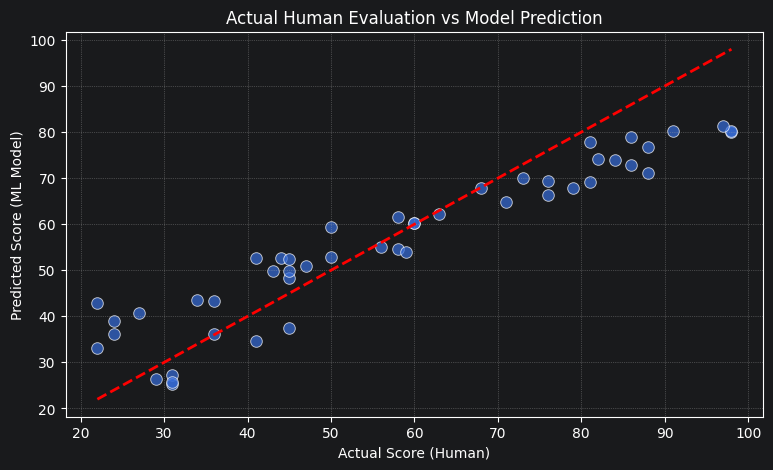

In [71]:
plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, s=70)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2)
plt.title('Actual Human Evaluation vs Model Prediction')
plt.xlabel('Actual Score (Human)')
plt.ylabel('Predicted Score (ML Model)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [73]:
import os
model_dir = '../models'
model_path = f'{model_dir}/CareerFit_Hybrid_Model.pkl'
os.makedirs(model_dir, exist_ok=True)
joblib.dump(model, model_path)
print("━" * 60)
print("✅ The dump process was successful!")
print(f"The AI engine weights are stored securely in the local path:\n {model_path}")
print("━" * 60)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
✅ The dump process was successful!
The AI engine weights are stored securely in the local path:
 ../models/CareerFit_Hybrid_Model.pkl
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
